In [1]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


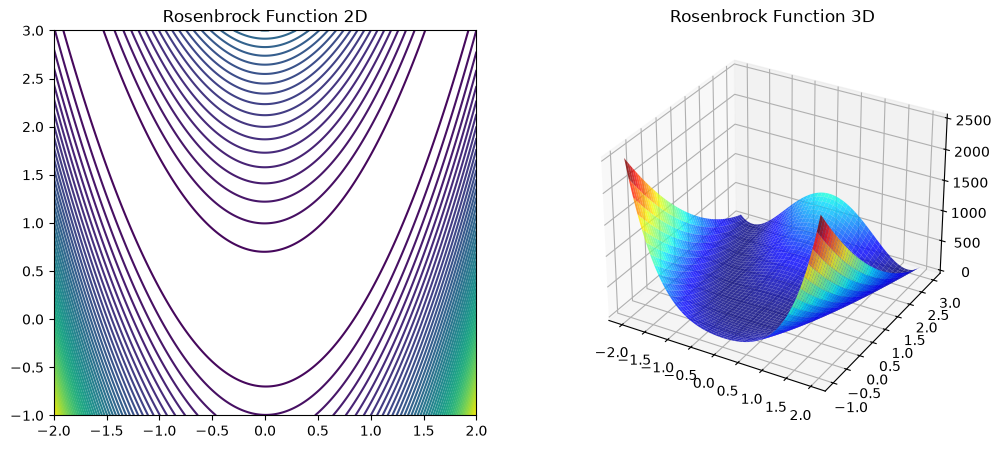

Initial guess [-3, 4], Result: [0.99999768 0.99999525], Value: 6.785835635230166e-12, Success: False, Iterations: 44, Time: 0.0619 sec
Initial guess [2.7, 1.5], Result: [0.99999627 0.99999253], Value: 1.3935717025308194e-11, Success: True, Iterations: 42, Time: 0.0210 sec
Initial guess [0.2, 0.1], Result: [0.9999954  0.99999077], Value: 2.123526198384174e-11, Success: True, Iterations: 19, Time: 0.0108 sec


c:\Users\ADMIN\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-3, 4], Solution: [0.99085819 0.98194752], Value: rosenbrock(solution), iterations: 2000, Time: 1.3876 sec


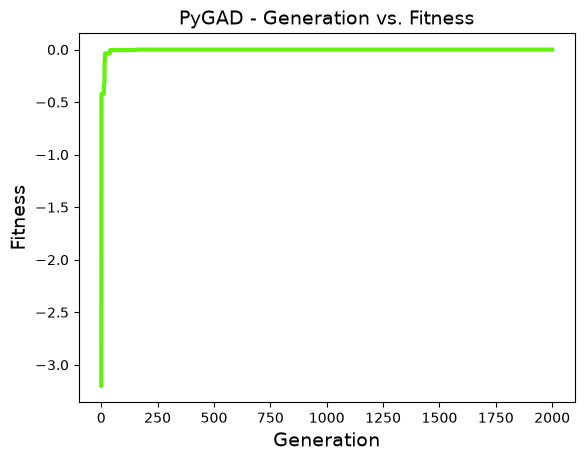

PyGAD initial guess [2.7, 1.5], Solution: [1.00548517 1.00905166], Value: rosenbrock(solution), iterations: 2000, Time: 1.5127 sec


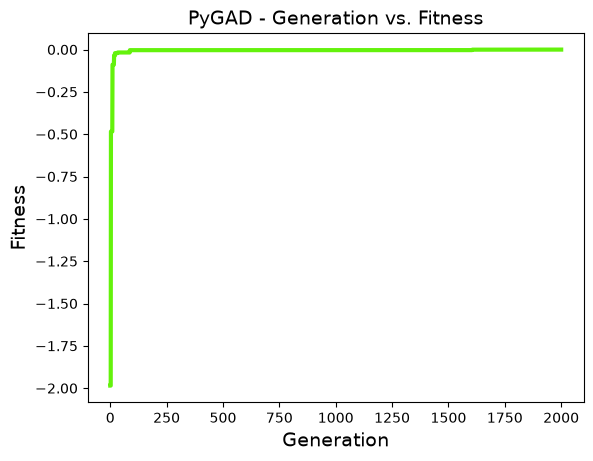

PyGAD initial guess [0.2, 0.1], Solution: [0.97237185 0.94659361], Value: rosenbrock(solution), iterations: 2000, Time: 1.5226 sec


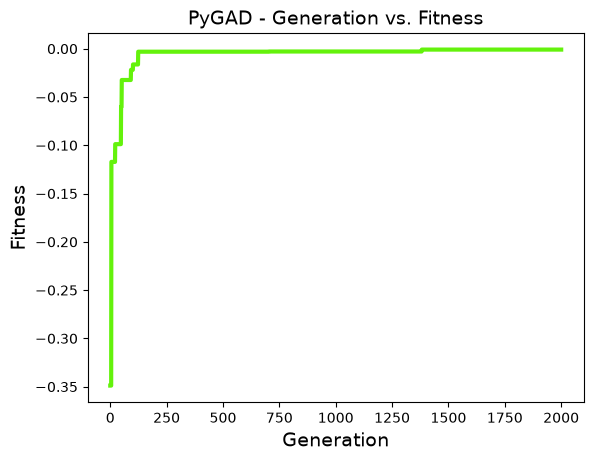

In [5]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []

numerical_solutions = []
# Scipy Optimization
init_guesses = [[-3, 4], [2.7, 1.5], [0.2, 0.1]]
numerical_solutions = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS',)
    numerical_solutions.append(result.x)
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    # Store numerical solution
    numerical_solutions.append(result.x)
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: rosenbrock(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")
    ga_instance.plot_fitness()

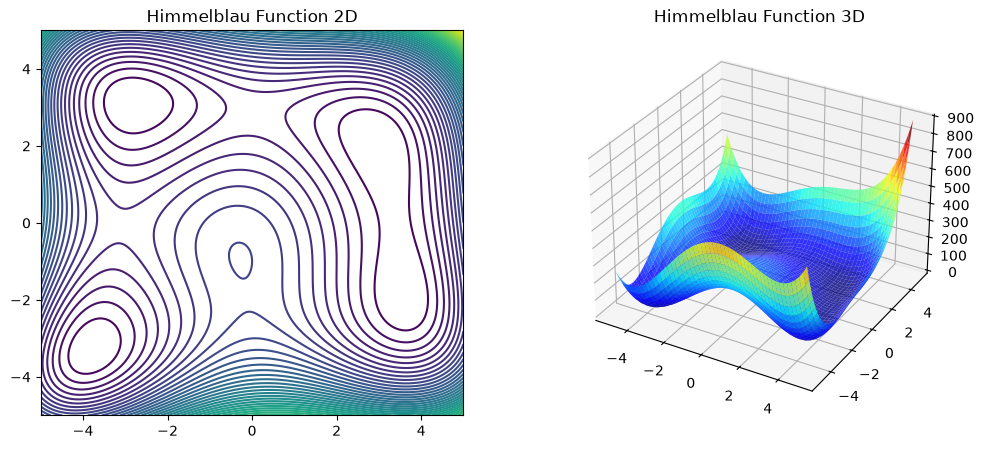

Initial guess [0, 0], Result: [2.99999994 1.99999999], Value: 1.3782273267389757e-13, Success: True, Iterations: 10, Time: 0.0121 sec
Initial guess [-4, 4], Result: [-2.80511803  3.13131251], Value: 1.0206446176713682e-13, Success: True, Iterations: 10, Time: 0.0053 sec
Initial guess [4, 0], Result: [ 3.58442834 -1.84812653], Value: 2.263853503678799e-16, Success: True, Iterations: 8, Time: 0.0057 sec
PyGAD initial guess [0, 0], Solution: [ 3.58866994 -1.86075537], Value: 0.0029259344217287607, Iterations: 300, Time: 0.3846 sec


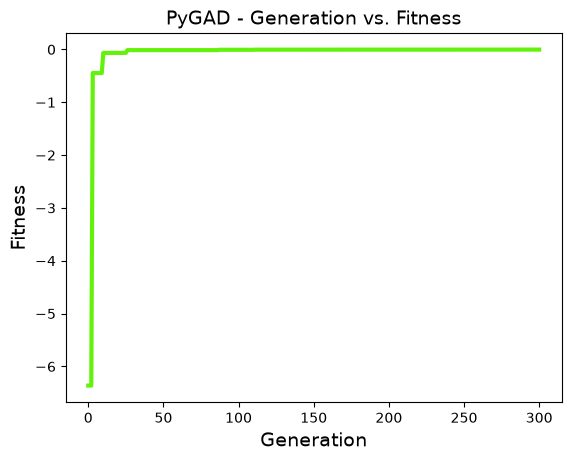

PyGAD initial guess [-4, 4], Solution: [3.01072317 1.9968944 ], Value: 0.0037664785803462777, Iterations: 300, Time: 0.3513 sec


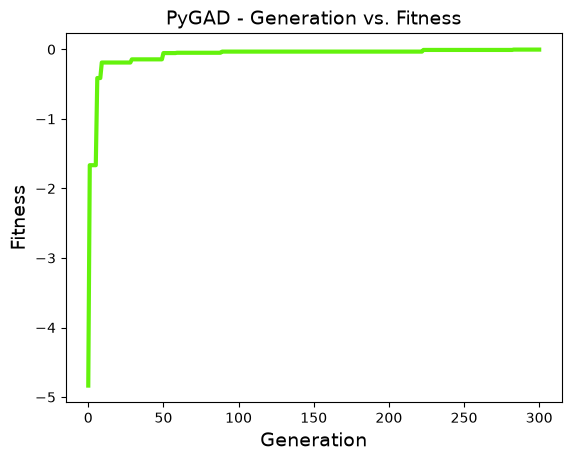

PyGAD initial guess [4, 0], Solution: [2.99647873 2.00263751], Value: 0.000390926333058895, Iterations: 300, Time: 0.3173 sec


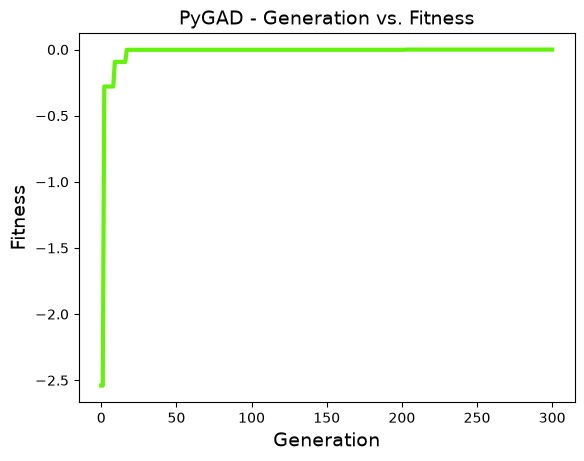

In [8]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[0, 0], [-4, 4], [4, 0]]
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, Iterations: {iters}, Time: {elapsed_time:.4f} sec")
    ga_instance.plot_fitness()